# LLM Reasoning Analysis Framework

This notebook provides a comprehensive framework for analyzing LLM reasoning across models and contexts.

## Overview
- **Part 1**: Traditional text analysis (length, vocabulary, factor detection)
- **Part 2**: LLM-as-a-judge evaluation (factual accuracy, context awareness, logical coherence)
- **Part 3**: Integrated analysis and comparison
- **Part 4**: Visualization and reporting

## Function Def


In [1]:
import pandas as pd
import numpy as np
import os
import glob
import re
import json
from collections import Counter
from typing import Dict, List, Tuple
import asyncio
import nest_asyncio
from openai import AsyncAzureOpenAI
import seaborn as sns
import matplotlib.pyplot as plt
import string
from scipy import stats

nest_asyncio.apply()

# Set random seeds for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("✓ All imports successful")

✓ All imports successful


In [2]:
# ================================
# CONFIGURATION
# ================================

# API Configuration
API_KEY = 'MmI5OWMyOWRhMmFhNGFkNTljNDhjNTEzMTIwZWRjNzM6NTlhYjI3ZDdiQzM1NEFiMkI5MjNmRTcwOUM0QUYwZEQ='
API_VERSION = '2024-10-21'
RESOURCE_ENDPOINT = 'https://unified-api.ucsf.edu/general'
JUDGE_MODEL = 'gpt-5-mini-2025-08-07'

# Analysis Configuration
TEMPERATURE = 1.0  # For LLM judge
RANDOM_SEED = 42
SUBSAMPLE_SIZE = 5 # Set to an integer (e.g., 10) for testing, or None for full run
CONCURRENCY = 128
RATE_DELAY = 0.1
MAX_RETRIES = 5

# Data paths
STRATEGIES = {
    'strategy_one': 'strategy_one_results',
    'strategy_two': 'strategy_two_results',
    'strategy_three': 'strategy_three_results',
    'strategy_four': 'strategy_four_results'
}

# Output directory
OUTPUT_DIR = './reasoning_analysis_results'

# Plotting configuration
FIG_SIZE_SINGLE = (10, 7)
FIG_SIZE_MULTI = (18, 14)
FONT_SCALE = 2.0
DPI = 300

sns.set_style("white")
sns.set_context("paper", font_scale=FONT_SCALE)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['figure.dpi'] = DPI

print("✓ Configuration complete")

✓ Configuration complete


In [3]:
# ================================
# PART 1: TRADITIONAL TEXT ANALYSIS
# ================================

class ReasoningAnalyzer:
    """Traditional text-based analysis of reasoning"""
    
    def __init__(self, df: pd.DataFrame):
        self.df = df.copy()
        
    def compute_basic_metrics(self) -> pd.DataFrame:
        """Calculate basic quantitative metrics for reasoning text"""
        
        # Length metrics
        self.df['reasoning_length'] = self.df['reasoning'].str.len()
        self.df['reasoning_word_count'] = self.df['reasoning'].str.split().str.len()
        self.df['reasoning_sentence_count'] = self.df['reasoning'].str.count(r'[.!?]+')
        self.df['avg_word_length'] = self.df['reasoning'].apply(
            lambda x: np.mean([len(word) for word in str(x).split()]) if pd.notna(x) and len(str(x).split()) > 0 else 0
        )
        self.df['avg_sentence_length'] = (
            self.df['reasoning_word_count'] / self.df['reasoning_sentence_count'].replace(0, 1)
        )
        
        return self.df
    
    def compute_vocabulary_diversity(self) -> pd.DataFrame:
        """Measure lexical diversity and complexity"""
        
        def type_token_ratio(text):
            """Unique words / total words"""
            if pd.isna(text) or len(str(text).split()) == 0:
                return 0
            words = str(text).lower().split()
            return len(set(words)) / len(words)
        
        self.df['vocabulary_diversity'] = self.df['reasoning'].apply(type_token_ratio)
        
        return self.df
    
    def detect_factor_mentions(self) -> pd.DataFrame:
        """Detect mentions of key decision factors"""
        
        # Define factor keywords
        factor_keywords = {
            'infection_rate': r'\b(infection|case|spread|disease|transmission|epidemic)\b',
            'npi_measures': r'\b(restriction|lockdown|mandate|measure|policy|intervention|npi)\b',
            'economic': r'\b(economic|economy|financial|business|cost|employment|job)\b',
            'capacity': r'\b(capacity|hospital|healthcare|resource|bed|facility)\b',
            'social': r'\b(social|community|public|people|population|society)\b',
            'comparative': r'\b(compar|versus|vs|between|option|alternative|choice)\b',
            'quantitative': r'\b(\d+%|\d+\.\d+|higher|lower|more|less|reduce|increase)\b',
            'causal': r'\b(because|therefore|thus|since|due to|as a result|leads to|causes)\b'
        }
        
        for factor, pattern in factor_keywords.items():
            self.df[f'mentions_{factor}'] = self.df['reasoning'].str.contains(
                pattern, case=False, na=False, regex=True
            ).astype(int)
        
        # Total factor coverage
        mention_cols = [col for col in self.df.columns if col.startswith('mentions_')]
        self.df['total_factors_mentioned'] = self.df[mention_cols].sum(axis=1)
        
        return self.df
    
    def detect_context_awareness(self) -> pd.DataFrame:
        """Check if context variables are explicitly mentioned"""
        
        # These will vary based on your strategies
        context_patterns = {
            'capacity_mentioned': r'\b(capacity|hospital|healthcare system)\b',
            'economic_mentioned': r'\b(economic|economy|financial impact)\b',
            'preference_mentioned': r'\b(prefer|preference|priority)\b'
        }
        
        for var, pattern in context_patterns.items():
            self.df[f'context_{var}'] = self.df['reasoning'].str.contains(
                pattern, case=False, na=False, regex=True
            ).astype(int)
        
        return self.df
    
    def compute_logical_structure_metrics(self) -> pd.DataFrame:
        """Analyze logical structure of reasoning"""
        
        # Count logical connectors
        self.df['has_comparison'] = self.df['reasoning'].str.contains(
            r'\b(however|whereas|while|although|but|compare|versus)\b',
            case=False, na=False, regex=True
        ).astype(int)
        
        self.df['has_causation'] = self.df['reasoning'].str.contains(
            r'\b(because|therefore|thus|hence|consequently|as a result)\b',
            case=False, na=False, regex=True
        ).astype(int)
        
        self.df['has_conclusion'] = self.df['reasoning'].str.contains(
            r'\b(therefore|thus|consequently|in conclusion|overall)\b',
            case=False, na=False, regex=True
        ).astype(int)
        
        return self.df
    
    def analyze_consistency_within_model(self) -> pd.DataFrame:
        """Calculate within-model consistency metrics"""
        
        # Group by model and similar contexts
        consistency_metrics = []
        
        for model in self.df['model'].unique():
            model_df = self.df[self.df['model'] == model]
            
            # Calculate variability in reasoning length
            length_mean = model_df['reasoning_word_count'].mean()
            length_cv = model_df['reasoning_word_count'].std() / length_mean if length_mean > 0 else 0
            
            # Calculate variability in factor mentions
            factor_cols = [col for col in self.df.columns if col.startswith('mentions_')]
            factor_consistency = model_df[factor_cols].std().mean()
            
            consistency_metrics.append({
                'model': model,
                'reasoning_length_cv': length_cv,
                'factor_mention_std': factor_consistency,
                'n_samples': len(model_df)
            })
        
        return pd.DataFrame(consistency_metrics)
    
    def generate_summary_statistics(self) -> pd.DataFrame:
        """Generate summary statistics by model and context"""
        
        # Group by model
        summary = self.df.groupby('model').agg({
            'reasoning_word_count': ['mean', 'std', 'min', 'max'],
            'vocabulary_diversity': ['mean', 'std'],
            'total_factors_mentioned': ['mean', 'std'],
            'has_comparison': 'mean',
            'has_causation': 'mean',
            'has_conclusion': 'mean'
        }).round(3)
        
        return summary

print("✓ ReasoningAnalyzer class defined")

✓ ReasoningAnalyzer class defined


In [4]:
# ================================
# PART 2: LLM-AS-A-JUDGE FRAMEWORK
# ================================

class LLMJudge:
    """LLM-based evaluation of reasoning quality"""
    
    def __init__(self, api_key: str, api_version: str, endpoint: str, seed: int = 42):
        self.client = AsyncAzureOpenAI(
            api_key=api_key,
            api_version=api_version,
            azure_endpoint=endpoint
        )
        self.sem = asyncio.Semaphore(CONCURRENCY)
        self.rate_delay = RATE_DELAY
        self.max_retries = MAX_RETRIES
        self.seed = seed
    
    def create_evaluation_prompts(self) -> Dict[str, str]:
        """
        Create separate evaluation prompts for different dimensions.
        Following best practice: use binary classification and chain-of-thought.
        """
        
        prompts = {
            'factual_accuracy': """You are evaluating the factual accuracy of reasoning provided by an LLM for a decision task.

Given the following information:
- Option Selected: {option_selected}
- NPI Level Selected: {npi_selected}
- Infection Rate Selected: {infection_rate_selected}
- NPI Level Non-Selected: {npi_non_selected}
- Infection Rate Non-Selected: {infection_rate_non_selected}
- Context: {context}

Reasoning to evaluate:
{reasoning}

Task: Evaluate whether the reasoning correctly represents the numerical values presented in the options.

First, analyze step-by-step:
1. Does the reasoning correctly identify which option has higher/lower infection rates?
2. Does the reasoning correctly identify which option has more/fewer restrictions?
3. Are the numerical comparisons accurate?

Then provide your evaluation in JSON format:
{{"analysis": "your step-by-step analysis here", "factually_accurate": true/false}}

Factually accurate means ALL numerical facts are correct. If any fact is wrong or misrepresented, mark as false.""",

            'context_awareness': """You are evaluating whether an LLM's reasoning demonstrates awareness of provided context.

Context provided: {context}
Context type: {context_type}

Reasoning to evaluate:
{reasoning}

Task: Determine if the reasoning explicitly considers or mentions the context provided.

First, analyze step-by-step:
1. Is the context variable mentioned or referenced?
2. Does the reasoning explain how context influences the decision?
3. Is the context integrated meaningfully (not just mentioned)?

Then provide your evaluation in JSON format:
{{"analysis": "your step-by-step analysis", "context_aware": true/false}}

Mark as true only if context is meaningfully integrated into the reasoning.""",

            'logical_coherence': """You are evaluating the logical coherence of reasoning.

Reasoning to evaluate:
{reasoning}

Decision made: Selected option with NPI={npi_selected}, Infection={infection_rate_selected}
            Over option with NPI={npi_non_selected}, Infection={infection_rate_non_selected}

Task: Evaluate whether the reasoning follows a logical structure and the conclusion matches the explanation.

First, analyze step-by-step:
1. Does the reasoning present clear criteria for decision-making?
2. Is there a logical flow from analysis to conclusion?
3. Does the stated reasoning actually support the choice made?
4. Are there internal contradictions?

Then provide your evaluation in JSON format:
{{"analysis": "your step-by-step analysis", "logically_coherent": true/false}}

Mark as true only if reasoning is coherent AND supports the decision made.""",

            'comparative_analysis': """You are evaluating whether reasoning includes comparative analysis.

Option A: NPI={npi_selected}, Infection={infection_rate_selected}
Option B: NPI={npi_non_selected}, Infection={infection_rate_non_selected}

Reasoning to evaluate:
{reasoning}

Task: Determine if the reasoning explicitly compares the two options.

First, analyze step-by-step:
1. Are both options mentioned or described?
2. Are trade-offs between options discussed?
3. Are specific differences highlighted?

Then provide your evaluation in JSON format:
{{"analysis": "your step-by-step analysis", "includes_comparison": true/false}}

Mark as true only if there is explicit comparison between the two options.""",

            'depth_of_analysis': """You are evaluating the depth and sophistication of reasoning.

Reasoning to evaluate:
{reasoning}

Task: Determine if the reasoning demonstrates sophisticated analysis beyond surface-level observations.

First, analyze step-by-step:
1. Does it go beyond simply stating the numbers?
2. Does it discuss implications, trade-offs, or broader considerations?
3. Does it show multi-factor thinking?
4. Is there evidence of weighing competing priorities?

Then provide your evaluation in JSON format:
{{"analysis": "your step-by-step analysis", "deep_analysis": true/false}}

Mark as true only if the analysis shows sophisticated, multi-dimensional thinking."""
        }
        
        return prompts
    
    async def evaluate_single_reasoning(
        self, 
        row: pd.Series, 
        prompt_template: str,
        model: str = "gpt-5-mini-2025-08-07",
        temperature: float = 1.0
    ) -> Dict:
        """Evaluate a single reasoning instance"""
        
        # Format the prompt with row data
        context_col = self._get_context_column(row.get('strategy', ''))
        context_value = row.get(context_col, 'None') if context_col else 'None'
        
        prompt = prompt_template.format(
            option_selected=row.get('option_selected', ''),
            npi_selected=row.get('npi_level_selected', ''),
            infection_rate_selected=row.get('infection_rate_selected', ''),
            npi_non_selected=row.get('npi_level_non_selected', ''),
            infection_rate_non_selected=row.get('infection_rate_non_selected', ''),
            context=context_value,
            context_type=context_col,
            reasoning=row.get('reasoning', '')
        )
        
        messages = [{"role": "user", "content": prompt}]
        
        # Retry logic
        backoff = 1.0
        for attempt in range(1, self.max_retries + 1):
            try:
                async with self.sem:
                    if self.rate_delay > 0:
                        await asyncio.sleep(self.rate_delay)
                    
                    response = await self.client.chat.completions.create(
                        model=model,
                        messages=messages,
                        temperature=temperature,
                        seed=self.seed,  # For reproducibility
                        response_format={"type": "json_object"},
                        timeout=30000
                    )
                
                result = json.loads(response.choices[0].message.content)
                return result
                
            except Exception as e:
                if attempt == self.max_retries:
                    print(f"[ERROR] Row index {row.name}: {type(e).__name__}: {e}")
                    return {"analysis": "ERROR", "result": None}
                await asyncio.sleep(backoff + np.random.random() * 0.25 * backoff)
                backoff = min(backoff * 2, 16)
    
    def _get_context_column(self, strategy_name: str) -> str:
        """Extract context column based on strategy"""
        strategy_num = int(''.join(filter(str.isdigit, strategy_name))) if any(c.isdigit() for c in strategy_name) else 0
        context_mapping = {
            2: 'capacity_context',
            3: 'economic_context',
            4: 'user_preference_type'
        }
        return context_mapping.get(strategy_num, None)
    
    async def evaluate_all_dimensions(
        self, 
        df: pd.DataFrame,
        model: str = "gpt-5-mini-2025-08-07",
        temperature: float = 1.0
    ) -> pd.DataFrame:
        """Evaluate all reasoning entries across all dimensions"""
        
        prompts = self.create_evaluation_prompts()
        results = df.copy()
        
        # Mapping from dimension to boolean key in JSON
        result_keys = {
            'factual_accuracy': 'factually_accurate',
            'context_awareness': 'context_aware',
            'logical_coherence': 'logically_coherent',
            'comparative_analysis': 'includes_comparison',
            'depth_of_analysis': 'deep_analysis'
        }
        
        for dimension, prompt_template in prompts.items():
            print(f"\nEvaluating dimension: {dimension}")
            
            tasks = [
                self.evaluate_single_reasoning(row, prompt_template, model, temperature)
                for _, row in df.iterrows()
            ]
            
            dimension_results = await asyncio.gather(*tasks)
            
            # Extract results with explicit key lookup
            expected_key = result_keys.get(dimension)
            
            analyses = []
            scores = []
            
            for r in dimension_results:
                analyses.append(r.get('analysis', 'Error'))
                
                # Try to get the specific score key
                val = r.get(expected_key)
                
                # If not found or null, try to find any boolean
                if val is None:
                    bool_vals = [v for k, v in r.items() if isinstance(v, bool) and k != 'analysis']
                    if bool_vals:
                        val = bool_vals[0]
                
                scores.append(val)
            
            results[f'{dimension}_analysis'] = analyses
            results[f'{dimension}_score'] = scores
        
        return results

print("✓ LLMJudge class defined")

✓ LLMJudge class defined


In [5]:
# ================================
# PART 3: INTEGRATED ANALYSIS PIPELINE
# ================================

class IntegratedReasoningAnalysis:
    """Combined traditional and LLM-based analysis"""
    
    def __init__(self, results_df: pd.DataFrame):
        self.df = results_df
        self.traditional_analyzer = ReasoningAnalyzer(results_df)
        
    def run_traditional_analysis(self) -> pd.DataFrame:
        """Run all traditional text analysis"""
        
        print("Running traditional text analysis...")
        self.df = self.traditional_analyzer.compute_basic_metrics()
        self.df = self.traditional_analyzer.compute_vocabulary_diversity()
        self.df = self.traditional_analyzer.detect_factor_mentions()
        self.df = self.traditional_analyzer.detect_context_awareness()
        self.df = self.traditional_analyzer.compute_logical_structure_metrics()
        
        print("Traditional analysis complete.")
        return self.df
    
    async def run_llm_judge_analysis(
        self,
        api_key: str,
        api_version: str,
        endpoint: str,
        model: str = "gpt-5-mini-2025-08-07",
        temperature: float = 1.0,
        seed: int = 42
    ) -> pd.DataFrame:
        """Run LLM-as-a-judge evaluation"""
        
        print("\nRunning LLM-as-a-judge evaluation...")
        judge = LLMJudge(api_key, api_version, endpoint, seed=seed)
        self.df = await judge.evaluate_all_dimensions(self.df, model, temperature)
        
        print("LLM judge evaluation complete.")
        return self.df
    
    def generate_model_comparison_report(self) -> pd.DataFrame:
        """Generate comprehensive comparison across models"""
        
        # Traditional metrics by model
        traditional_cols = [
            'reasoning_word_count', 'vocabulary_diversity',
            'total_factors_mentioned', 'has_comparison',
            'has_causation', 'has_conclusion'
        ]
        
        # LLM judge metrics by model
        judge_cols = [col for col in self.df.columns if col.endswith('_score')]
        
        # Create aggregation dict
        agg_dict = {col: 'mean' for col in traditional_cols if col in self.df.columns}
        
        # For judge scores, convert True/False to 1/0 and calculate mean
        for col in judge_cols:
            if col in self.df.columns:
                agg_dict[col] = lambda x: pd.to_numeric(x, errors='coerce').mean()
        
        comparison = self.df.groupby('model').agg(agg_dict).round(3)
        
        return comparison
    
    def generate_context_comparison_report(self, context_col: str) -> pd.DataFrame:
        """Generate comparison across different contexts"""
        
        if context_col not in self.df.columns:
            print(f"Warning: {context_col} not found in dataframe")
            return pd.DataFrame()
        
        agg_dict = {
            'reasoning_word_count': 'mean',
            'total_factors_mentioned': 'mean'
        }
        
        if 'context_awareness_score' in self.df.columns:
            agg_dict['context_awareness_score'] = lambda x: x.astype(float).mean()
        
        comparison = self.df.groupby(['model', context_col]).agg(agg_dict).round(3)
        
        return comparison
    
    def save_results(self, output_dir: str = './reasoning_analysis_results'):
        """Save all analysis results"""
        
        os.makedirs(output_dir, exist_ok=True)
        
        # Save full analyzed dataset
        self.df.to_csv(f'{output_dir}/full_analysis.csv', index=False)
        
        # Save model comparison
        model_comparison = self.generate_model_comparison_report()
        model_comparison.to_csv(f'{output_dir}/model_comparison.csv')
        
        # Save consistency metrics
        consistency = self.traditional_analyzer.analyze_consistency_within_model()
        consistency.to_csv(f'{output_dir}/model_consistency.csv', index=False)
        
        print(f"\nResults saved to {output_dir}/")
        
        return output_dir

print("✓ IntegratedReasoningAnalysis class defined")

✓ IntegratedReasoningAnalysis class defined


## Data Loading

Load and combine data from all strategy directories.

In [6]:
# Load data from all strategies
all_dfs = []

for strategy_name, directory in STRATEGIES.items():
    dir_path = os.path.join('.', directory)
    if not os.path.exists(dir_path):
        print(f"Warning: Directory '{dir_path}' not found. Skipping...")
        continue
        
    csv_files = glob.glob(os.path.join(dir_path, 'results_*.csv'))
    
    for csv_file in csv_files:
        filename = os.path.basename(csv_file)
        df = pd.read_csv(csv_file)
        df['strategy'] = strategy_name
        all_dfs.append(df)
        print(f"  Loaded: {filename} ({len(df)} rows)")

if all_dfs:
    results_df = pd.concat(all_dfs, ignore_index=True)
    print(f"\n✓ Successfully combined {len(all_dfs)} files. Total rows: {len(results_df)}")
    
    # Apply subsampling if configured
    if SUBSAMPLE_SIZE is not None and SUBSAMPLE_SIZE > 0:
        print(f"\nApplying subsampling: {SUBSAMPLE_SIZE} samples per model/strategy...")
        try:
            # Group by model and strategy, then sample
            results_df = results_df.groupby(['model', 'strategy'], group_keys=False).apply(
                lambda x: x.sample(min(len(x), SUBSAMPLE_SIZE), random_state=RANDOM_SEED)
            )
            print(f"✓ Subsampling complete. New total rows: {len(results_df)}")
        except Exception as e:
            print(f"Warning: Subsampling failed: {e}. Using full dataset.")
    print(f"✓ Models found: {results_df['model'].unique().tolist()}")
    print(f"✓ Strategies found: {results_df['strategy'].unique().tolist()}")
else:
    print("❌ No data files were found or loaded.")
    results_df = pd.DataFrame()

# Display sample
if not results_df.empty:
    print("\nFirst few rows:")
    display(results_df.head())
    print(f"\nColumns: {results_df.columns.tolist()}")

  Loaded: results_deepseek_deepseek-chat-v3.1.csv (144 rows)
  Loaded: results_x-ai_grok-4-fast.csv (144 rows)
  Loaded: results_openai_gpt-5-nano.csv (144 rows)
  Loaded: results_google_gemini-2.5-flash.csv (144 rows)
  Loaded: results_deepseek_deepseek-chat-v3.1.csv (432 rows)
  Loaded: results_x-ai_grok-4-fast.csv (432 rows)
  Loaded: results_openai_gpt-5-nano.csv (432 rows)
  Loaded: results_google_gemini-2.5-flash.csv (432 rows)
  Loaded: results_deepseek_deepseek-chat-v3.1.csv (432 rows)
  Loaded: results_x-ai_grok-4-fast.csv (432 rows)
  Loaded: results_openai_gpt-5-nano.csv (432 rows)
  Loaded: results_google_gemini-2.5-flash.csv (432 rows)
  Loaded: results_deepseek_deepseek-chat-v3.1.csv (576 rows)
  Loaded: results_openai_gpt-5-nano.csv (576 rows)

✓ Successfully combined 14 files. Total rows: 5184

Applying subsampling: 5 samples per model/strategy...
✓ Subsampling complete. New total rows: 70
✓ Models found: ['deepseek/deepseek-chat-v3.1', 'google/gemini-2.5-flash', 'opena

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_51035/821847735.py:28: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results_df = results_df.groupby(['model', 'strategy'], group_keys=False).apply(


,id,timestamp,model,temperature,pair,option_1,option_2,selected_choice,response_text,reasoning,infection_rate_selected,npi_level_selected,infection_rate_non_selected,npi_level_non_selected,strategy,capacity_context,economic_context,user_preference_type,preferred_option_num
4266,deepseek_deepseek-chat-v3.1_D_F_Maximize_Infec...,2025-12-05T01:57:56.851446,deepseek/deepseek-chat-v3.1,0.1,D-F,"Option D. Crowded, high-risk businesses (such ...","Option F. Crowded, high-risk businesses (such ...",D,1,"Of course. As a public health official, my rea...",1,1,20,1,strategy_four,NaN,NaN,Maximize Infection,2.0
4150,deepseek_deepseek-chat-v3.1_F_H_Minimize_NPI_t...,2025-12-05T01:49:11.424310,deepseek/deepseek-chat-v3.1,0.1,F-H,"Option F. Crowded, high-risk businesses (such ...",Option H. All non-essential businesses (such a...,F,1,"Of course. As a public health official, my rea...",20,1,10,2,strategy_four,NaN,NaN,Minimize NPI,1.0
4378,deepseek_deepseek-chat-v3.1_B_H_Maximize_Infec...,2025-12-05T02:06:15.721334,deepseek/deepseek-chat-v3.1,0.1,B-H,Option B. No businesses are closed; 10 in 100 ...,Option H. All non-essential businesses (such a...,B,1,"As a public health official, my primary goal i...",10,0,10,2,strategy_four,NaN,NaN,Maximize Infection,1.0
4530,deepseek_deepseek-chat-v3.1_G_I_Maximize_NPI_t...,2025-12-05T02:16:29.323502,deepseek/deepseek-chat-v3.1,0.7,G-I,Option G. All non-essential businesses (such a...,Option I. All non-essential businesses (such a...,G,1,"Of course. As a public health official, my rea...",1,2,20,2,strategy_four,NaN,NaN,Maximize NPI,1.0
4434,deepseek_deepseek-chat-v3.1_H_B_Maximize_Infec...,2025-12-05T02:09:31.838428,deepseek/deepseek-chat-v3.1,0.1,H-B,Option H. All non-essential businesses (such a...,Option B. No businesses are closed; 10 in 100 ...,B,2,"Of course. As a public health official, my rea...",10,0,10,2,strategy_four,NaN,NaN,Maximize Infection,2.0



Columns: ['id', 'timestamp', 'model', 'temperature', 'pair', 'option_1', 'option_2', 'selected_choice', 'response_text', 'reasoning', 'infection_rate_selected', 'npi_level_selected', 'infection_rate_non_selected', 'npi_level_non_selected', 'strategy', 'capacity_context', 'economic_context', 'user_preference_type', 'preferred_option_num']


## Run Traditional Text Analysis

This section computes:
- Basic metrics (word count, sentence count, vocabulary diversity)
- Factor detection (infection rate, NPI measures, economic factors, etc.)
- Context awareness
- Logical structure markers

In [7]:
# Initialize analyzer
analyzer = IntegratedReasoningAnalysis(results_df)

# Run traditional analysis
analyzed_df = analyzer.run_traditional_analysis()

# Display summary statistics
print("\n" + "="*60)
print("TRADITIONAL ANALYSIS SUMMARY")
print("="*60)

summary_stats = analyzer.traditional_analyzer.generate_summary_statistics()
display(summary_stats)

# Show consistency metrics
print("\n" + "="*60)
print("MODEL CONSISTENCY METRICS")
print("="*60)
consistency = analyzer.traditional_analyzer.analyze_consistency_within_model()
display(consistency)

Running traditional text analysis...
Traditional analysis complete.

TRADITIONAL ANALYSIS SUMMARY


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_51035/1470837350.py:57: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  self.df[f'mentions_{factor}'] = self.df['reasoning'].str.contains(
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_51035/1470837350.py:57: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  self.df[f'mentions_{factor}'] = self.df['reasoning'].str.contains(
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_51035/1470837350.py:57: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  self.df[f'mentions_{factor}'] = self.df['reasoning'].str.contains(
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_51035/1470837350.py:57: UserWarning: This pattern is interpreted as a regular expressi

reasoning_word_count                     \
                                            mean      std  min  max   
model                                                                 
deepseek/deepseek-chat-v3.1                364.1  120.078  159  578   
google/gemini-2.5-flash                    450.6  192.175  112  861   
openai/gpt-5-nano                          136.6   59.533    1  243   
x-ai/grok-4-fast                           570.4  171.016  226  752   

                            vocabulary_diversity         \
                                            mean    std   
model                                                     
deepseek/deepseek-chat-v3.1                0.582  0.048   
google/gemini-2.5-flash                    0.530  0.068   
openai/gpt-5-nano                          0.729  0.086   
x-ai/grok-4-fast                           0.619  0.037   

                            total_factors_mentioned        has_comparison  \
                                               mean    std           mean   
model                                                                       
deepseek/deepseek-chat-v3.1                   7.200  0.616           0.95   
google/gemini-2.5-flash                       7.133  0.743           1.00   
openai/gpt-5-nano                             5.400  1.501           0.75   
x-ai/grok-4-fast                              7.400  0.737           1.00   

                            has_causation has_conclusion  
                                     mean           mean  
model                                                     
deepseek/deepseek-chat-v3.1         0.850          0.900  
google/gemini-2.5-flash             0.733          0.667  
openai/gpt-5-nano                   0.250          0.350  
x-ai/grok-4-fast                    0.200          0.667


MODEL CONSISTENCY METRICS


,model,reasoning_length_cv,factor_mention_std,n_samples
0,deepseek/deepseek-chat-v3.1,0.329793,0.203972,20
1,google/gemini-2.5-flash,0.426487,0.157818,15
2,openai/gpt-5-nano,0.435818,0.347497,20
3,x-ai/grok-4-fast,0.299818,0.118211,15


## Run LLM-as-a-Judge Analysis

This section evaluates reasoning quality across five dimensions:
1. **Factual Accuracy**: Are numerical values correctly represented?
2. **Context Awareness**: Is provided context meaningfully integrated?
3. **Logical Coherence**: Does reasoning support the decision?
4. **Comparative Analysis**: Are both options explicitly compared?
5. **Depth of Analysis**: Does it show sophisticated thinking?

⚠️ **Note**: This will make API calls and may take several minutes depending on dataset size.

In [8]:
# Run LLM judge analysis
# This is async, so we need to use await in notebook

analyzed_df = await analyzer.run_llm_judge_analysis(
    api_key=API_KEY,
    api_version=API_VERSION,
    endpoint=RESOURCE_ENDPOINT,
    model=JUDGE_MODEL,
    temperature=TEMPERATURE,
    seed=RANDOM_SEED
)

print("\n✓ LLM judge analysis complete!")
print(f"\nJudge evaluation columns added:")
judge_cols = [col for col in analyzed_df.columns if '_score' in col or '_analysis' in col]
for col in sorted(judge_cols):
    print(f"  - {col}")


Running LLM-as-a-judge evaluation...



Evaluating dimension: factual_accuracy

Evaluating dimension: context_awareness

Evaluating dimension: logical_coherence

Evaluating dimension: comparative_analysis

Evaluating dimension: depth_of_analysis
LLM judge evaluation complete.

✓ LLM judge analysis complete!

Judge evaluation columns added:
  - comparative_analysis_analysis
  - comparative_analysis_score
  - context_awareness_analysis
  - context_awareness_score
  - depth_of_analysis_analysis
  - depth_of_analysis_score
  - factual_accuracy_analysis
  - factual_accuracy_score
  - logical_coherence_analysis
  - logical_coherence_score


## Model Comparison Report

Compare all models across traditional metrics and LLM judge scores.

In [9]:
# Generate comprehensive model comparison
model_comparison = analyzer.generate_model_comparison_report()

print("="*80)
print("MODEL COMPARISON REPORT")
print("="*80)
display(model_comparison)

# Calculate overall quality score (average of all LLM judge scores)
judge_score_cols = [col for col in analyzed_df.columns if col.endswith('_score')]
if judge_score_cols:
    analyzed_df['overall_judge_score'] = analyzed_df[judge_score_cols].astype(float).mean(axis=1)
    
    overall_by_model = analyzed_df.groupby('model')['overall_judge_score'].mean().sort_values(ascending=False)
    
    print("\n" + "="*80)
    print("OVERALL QUALITY RANKING (by average LLM judge score)")
    print("="*80)
    for i, (model, score) in enumerate(overall_by_model.items(), 1):
        print(f"{i}. {model}: {score:.3f}")

MODEL COMPARISON REPORT


,reasoning_word_count,vocabulary_diversity,total_factors_mentioned,has_comparison,has_causation,has_conclusion,factual_accuracy_score,context_awareness_score,logical_coherence_score,comparative_analysis_score,depth_of_analysis_score
model,,,,,,,,,,,
deepseek/deepseek-chat-v3.1,364.1,0.582,7.200,0.95,0.850,0.900,0.500,0.0,0.650,1.00,0.450
google/gemini-2.5-flash,450.6,0.530,7.133,1.00,0.733,0.667,0.600,0.0,0.933,1.00,0.467
openai/gpt-5-nano,136.6,0.729,5.400,0.75,0.250,0.350,0.500,0.0,0.850,0.95,0.150
x-ai/grok-4-fast,570.4,0.619,7.400,1.00,0.200,0.667,0.733,0.0,0.667,1.00,0.733



OVERALL QUALITY RANKING (by average LLM judge score)
1. x-ai/grok-4-fast: 0.627
2. google/gemini-2.5-flash: 0.600
3. deepseek/deepseek-chat-v3.1: 0.520
4. openai/gpt-5-nano: 0.490


## Context-Specific Analysis

Analyze how models perform under different context conditions.

In [10]:
# Analyze by strategy and context
for strategy in analyzed_df['strategy'].unique():
    strategy_df = analyzed_df[analyzed_df['strategy'] == strategy]
    
    # Determine context column for this strategy
    strategy_num = int(''.join(filter(str.isdigit, strategy))) if any(c.isdigit() for c in strategy) else 0
    context_mapping = {
        2: 'capacity_context',
        3: 'economic_context',
        4: 'user_preference_type'
    }
    context_col = context_mapping.get(strategy_num, None)
    
    print(f"\n{'='*80}")
    print(f"STRATEGY: {strategy}")
    if context_col and context_col in strategy_df.columns:
        print(f"Context Variable: {context_col}")
        print(f"{'='*80}")
        
        context_report = analyzer.generate_context_comparison_report(context_col)
        if not context_report.empty:
            display(context_report)
    else:
        print(f"{'='*80}")
        print("No context variable for this strategy")
        
        # Show model comparison for this strategy
        strategy_comparison = strategy_df.groupby('model').agg({
            'reasoning_word_count': 'mean',
            'total_factors_mentioned': 'mean',
            'has_comparison': 'mean'
        }).round(3)
        display(strategy_comparison)


STRATEGY: strategy_four
No context variable for this strategy


,reasoning_word_count,total_factors_mentioned,has_comparison
model,,,
deepseek/deepseek-chat-v3.1,339.6,6.8,0.8
openai/gpt-5-nano,151.2,5.8,0.8



STRATEGY: strategy_one
No context variable for this strategy


,reasoning_word_count,total_factors_mentioned,has_comparison
model,,,
deepseek/deepseek-chat-v3.1,302.8,7.2,1.0
google/gemini-2.5-flash,368.4,7.4,1.0
openai/gpt-5-nano,100.2,4.6,0.6
x-ai/grok-4-fast,449.2,7.4,1.0



STRATEGY: strategy_three
No context variable for this strategy


,reasoning_word_count,total_factors_mentioned,has_comparison
model,,,
deepseek/deepseek-chat-v3.1,340.4,7.2,1.0
google/gemini-2.5-flash,569.4,7.0,1.0
openai/gpt-5-nano,150.2,5.2,0.8
x-ai/grok-4-fast,693.0,7.8,1.0



STRATEGY: strategy_two
No context variable for this strategy


,reasoning_word_count,total_factors_mentioned,has_comparison
model,,,
deepseek/deepseek-chat-v3.1,473.6,7.6,1.0
google/gemini-2.5-flash,414.0,7.0,1.0
openai/gpt-5-nano,144.8,6.0,0.8
x-ai/grok-4-fast,569.0,7.0,1.0


## Visualizations

Create visual comparisons of reasoning quality across models.

In [11]:
# analyzed_df = pd.read_csv('reasoning_analysis_results/full_analysis.csv')

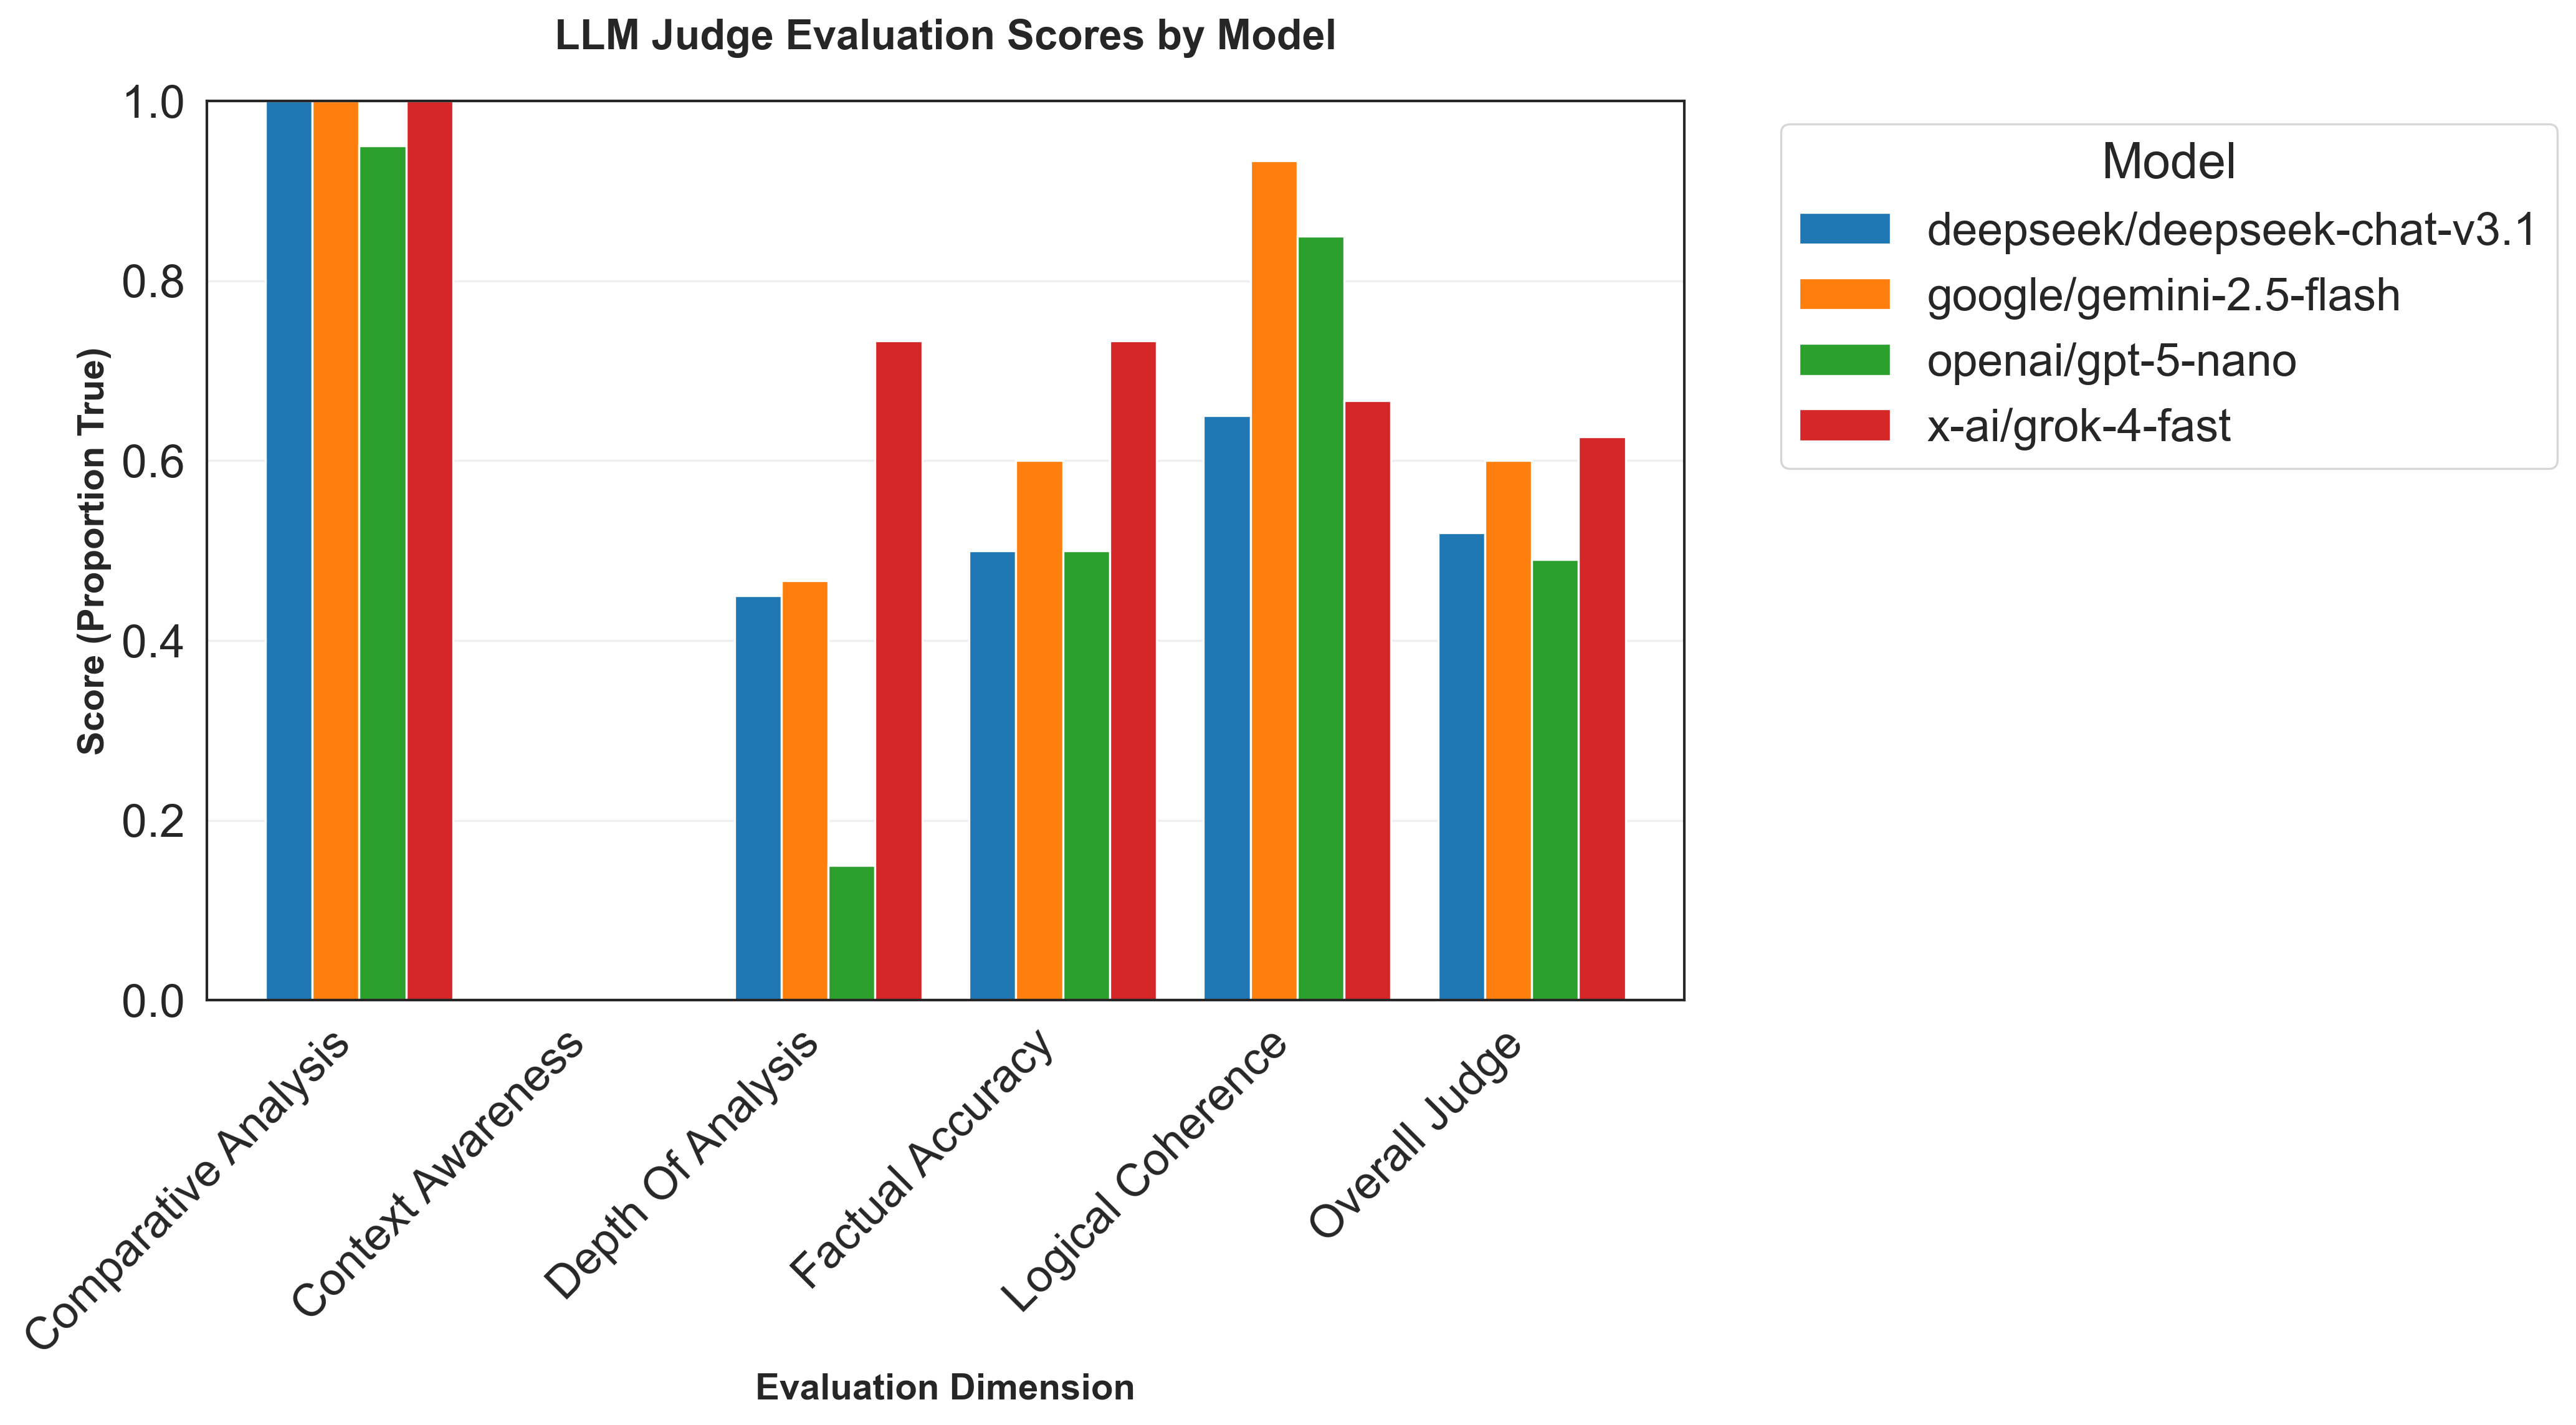


✓ LLM Judge Scores visualization complete


In [12]:
# Plot 1: LLM Judge Scores by Model
judge_score_cols = [col for col in analyzed_df.columns if col.endswith('_score')]

if judge_score_cols:
    # Prepare data for plotting
    plot_data = []
    for col in judge_score_cols:
        dimension = col.replace('_score', '').replace('_', ' ').title()
        for model in analyzed_df['model'].unique():
            model_data = analyzed_df[analyzed_df['model'] == model][col].astype(float)
            score = model_data.mean()
            plot_data.append({
                'Model': model,
                'Dimension': dimension,
                'Score': score
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Create grouped bar plot
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Pivot for grouped bar chart
    pivot_df = plot_df.pivot(index='Dimension', columns='Model', values='Score')
    pivot_df.plot(kind='bar', ax=ax, width=0.8)
    
    ax.set_xlabel('Evaluation Dimension', fontsize=14, fontweight='bold')
    ax.set_ylabel('Score (Proportion True)', fontsize=14, fontweight='bold')
    ax.set_title('LLM Judge Evaluation Scores by Model', fontsize=16, fontweight='bold', pad=20)
    ax.set_ylim(0, 1)
    ax.legend(title='Model', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    print("\n✓ LLM Judge Scores visualization complete")

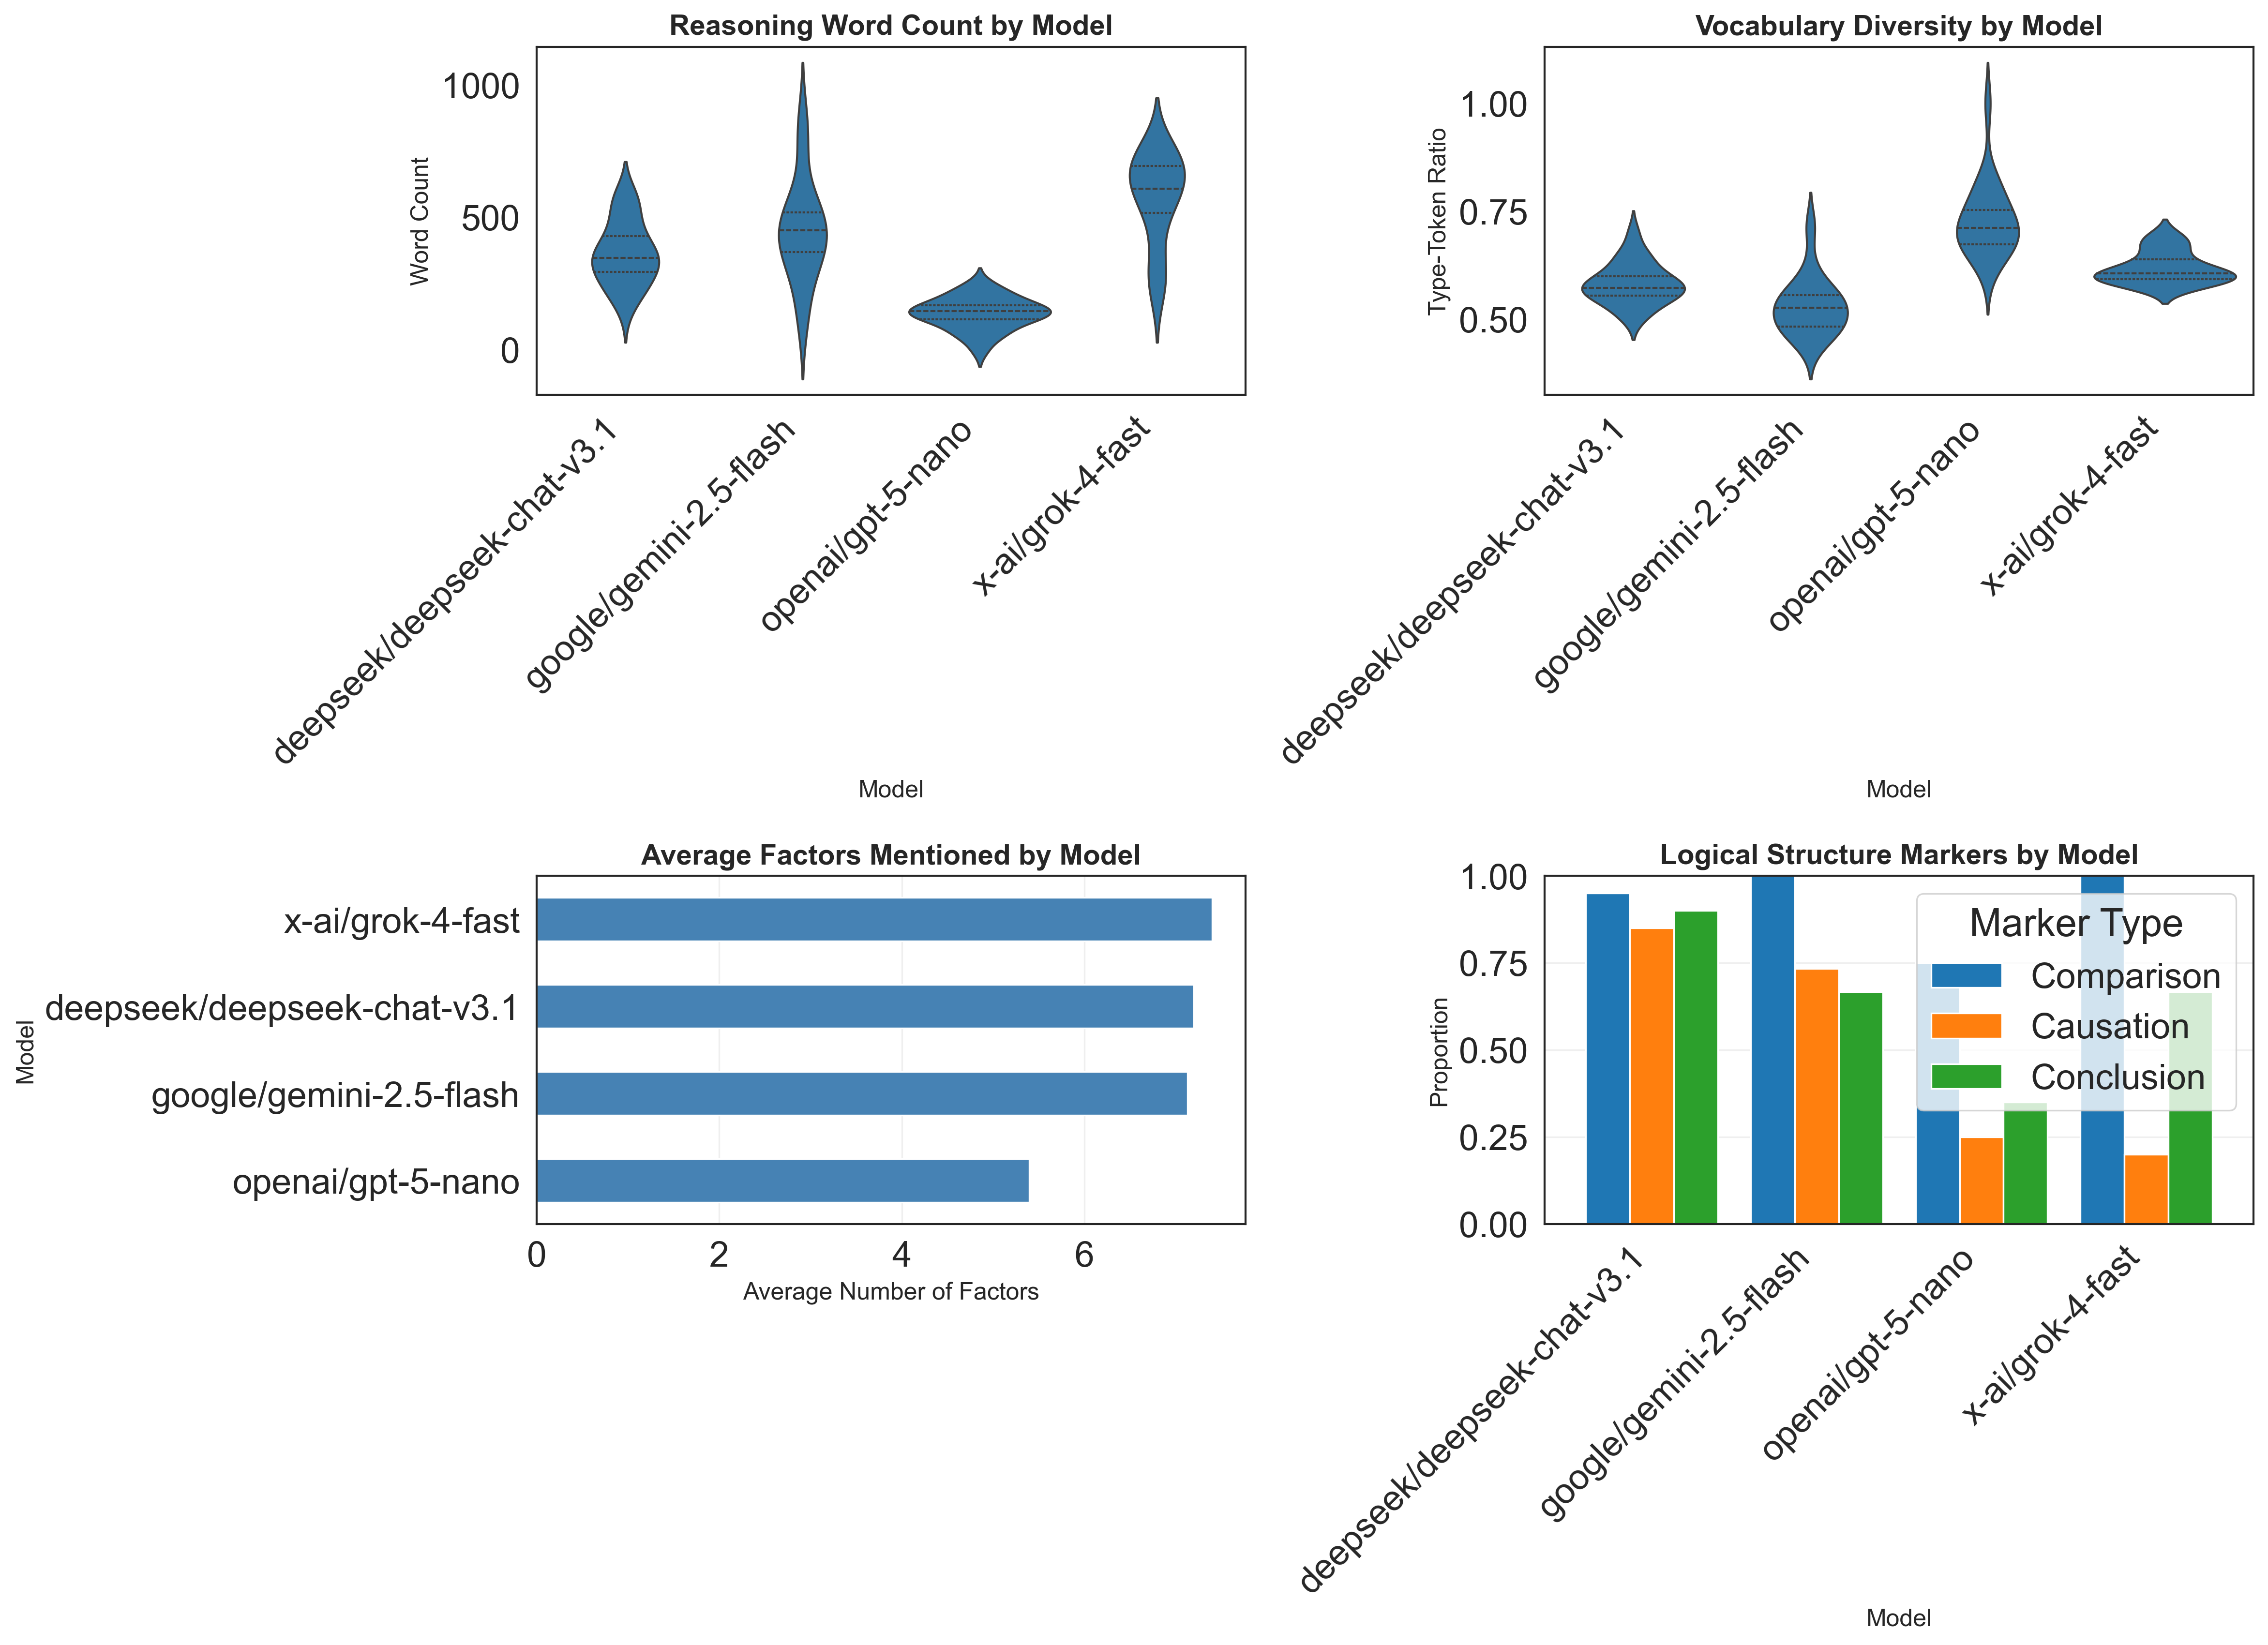


✓ Traditional metrics visualization complete


In [13]:
# Plot 2: Traditional Metrics by Model
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Word count distribution
# Violin plot for word count
sns.violinplot(data=analyzed_df, x='model', y='reasoning_word_count', ax=axes[0, 0], inner='quartile')
axes[0, 0].set_title('Reasoning Word Count by Model', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Model', fontsize=12)
axes[0, 0].set_ylabel('Word Count', fontsize=12)
plt.sca(axes[0, 0])
plt.xticks(rotation=45, ha='right')

# Vocabulary diversity
# Violin plot for vocabulary diversity
sns.violinplot(data=analyzed_df, x='model', y='vocabulary_diversity', ax=axes[0, 1], inner='quartile')
axes[0, 1].set_title('Vocabulary Diversity by Model', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Model', fontsize=12)
axes[0, 1].set_ylabel('Type-Token Ratio', fontsize=12)
plt.sca(axes[0, 1])
plt.xticks(rotation=45, ha='right')

# Total factors mentioned
factor_means = analyzed_df.groupby('model')['total_factors_mentioned'].mean().sort_values()
factor_means.plot(kind='barh', ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Average Factors Mentioned by Model', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Average Number of Factors', fontsize=12)
axes[1, 0].set_ylabel('Model', fontsize=12)
axes[1, 0].grid(axis='x', alpha=0.3)

# Logical structure markers
structure_cols = ['has_comparison', 'has_causation', 'has_conclusion']
structure_data = analyzed_df.groupby('model')[structure_cols].mean()
structure_data.plot(kind='bar', ax=axes[1, 1], width=0.8)
axes[1, 1].set_title('Logical Structure Markers by Model', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Model', fontsize=12)
axes[1, 1].set_ylabel('Proportion', fontsize=12)
axes[1, 1].legend(title='Marker Type', labels=['Comparison', 'Causation', 'Conclusion'])
axes[1, 1].set_ylim(0, 1)
plt.sca(axes[1, 1])
plt.xticks(rotation=45, ha='right')
axes[1, 1].grid(axis='y', alpha=0.3)

# Remove default titles
for ax in axes.flat:
    ax.get_figure().suptitle('')

plt.tight_layout()
plt.show()

print("\n✓ Traditional metrics visualization complete")

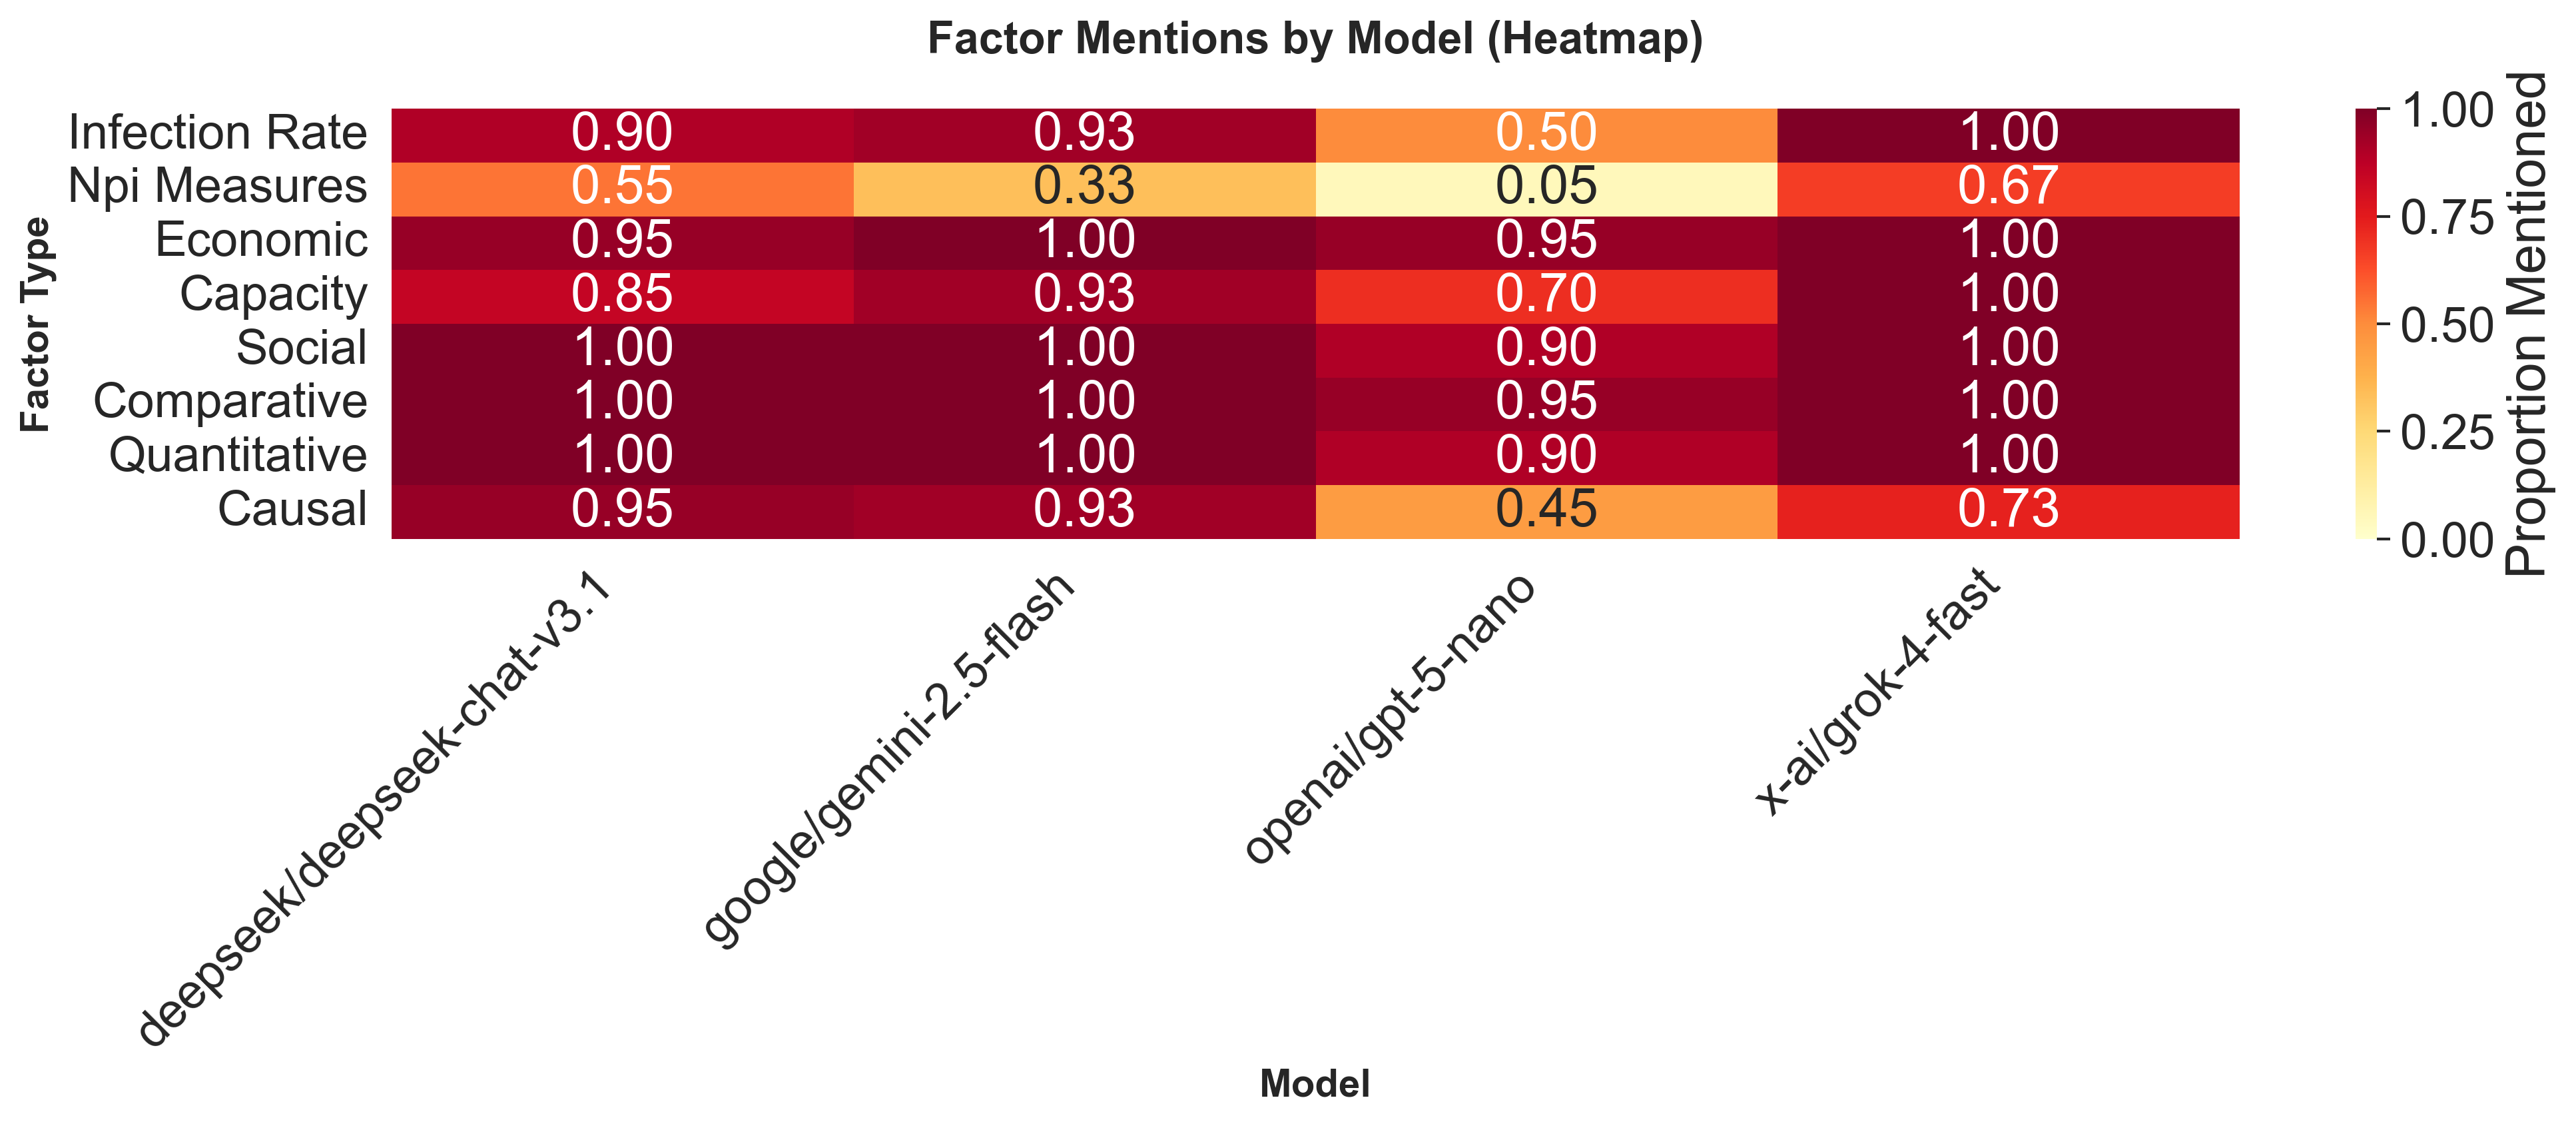


✓ Factor detection heatmap complete


In [14]:
# Plot 3: Factor Detection Heatmap
factor_cols = [col for col in analyzed_df.columns if col.startswith('mentions_')]

if factor_cols:
    factor_data = analyzed_df.groupby('model')[factor_cols].mean()
    factor_data.columns = [col.replace('mentions_', '').replace('_', ' ').title() for col in factor_data.columns]
    
    fig, ax = plt.subplots(figsize=(14, 6))
    sns.heatmap(factor_data.T, annot=True, fmt='.2f', cmap='YlOrRd', 
                cbar_kws={'label': 'Proportion Mentioned'}, ax=ax, vmin=0, vmax=1)
    ax.set_title('Factor Mentions by Model (Heatmap)', fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Model', fontsize=14, fontweight='bold')
    ax.set_ylabel('Factor Type', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Factor detection heatmap complete")

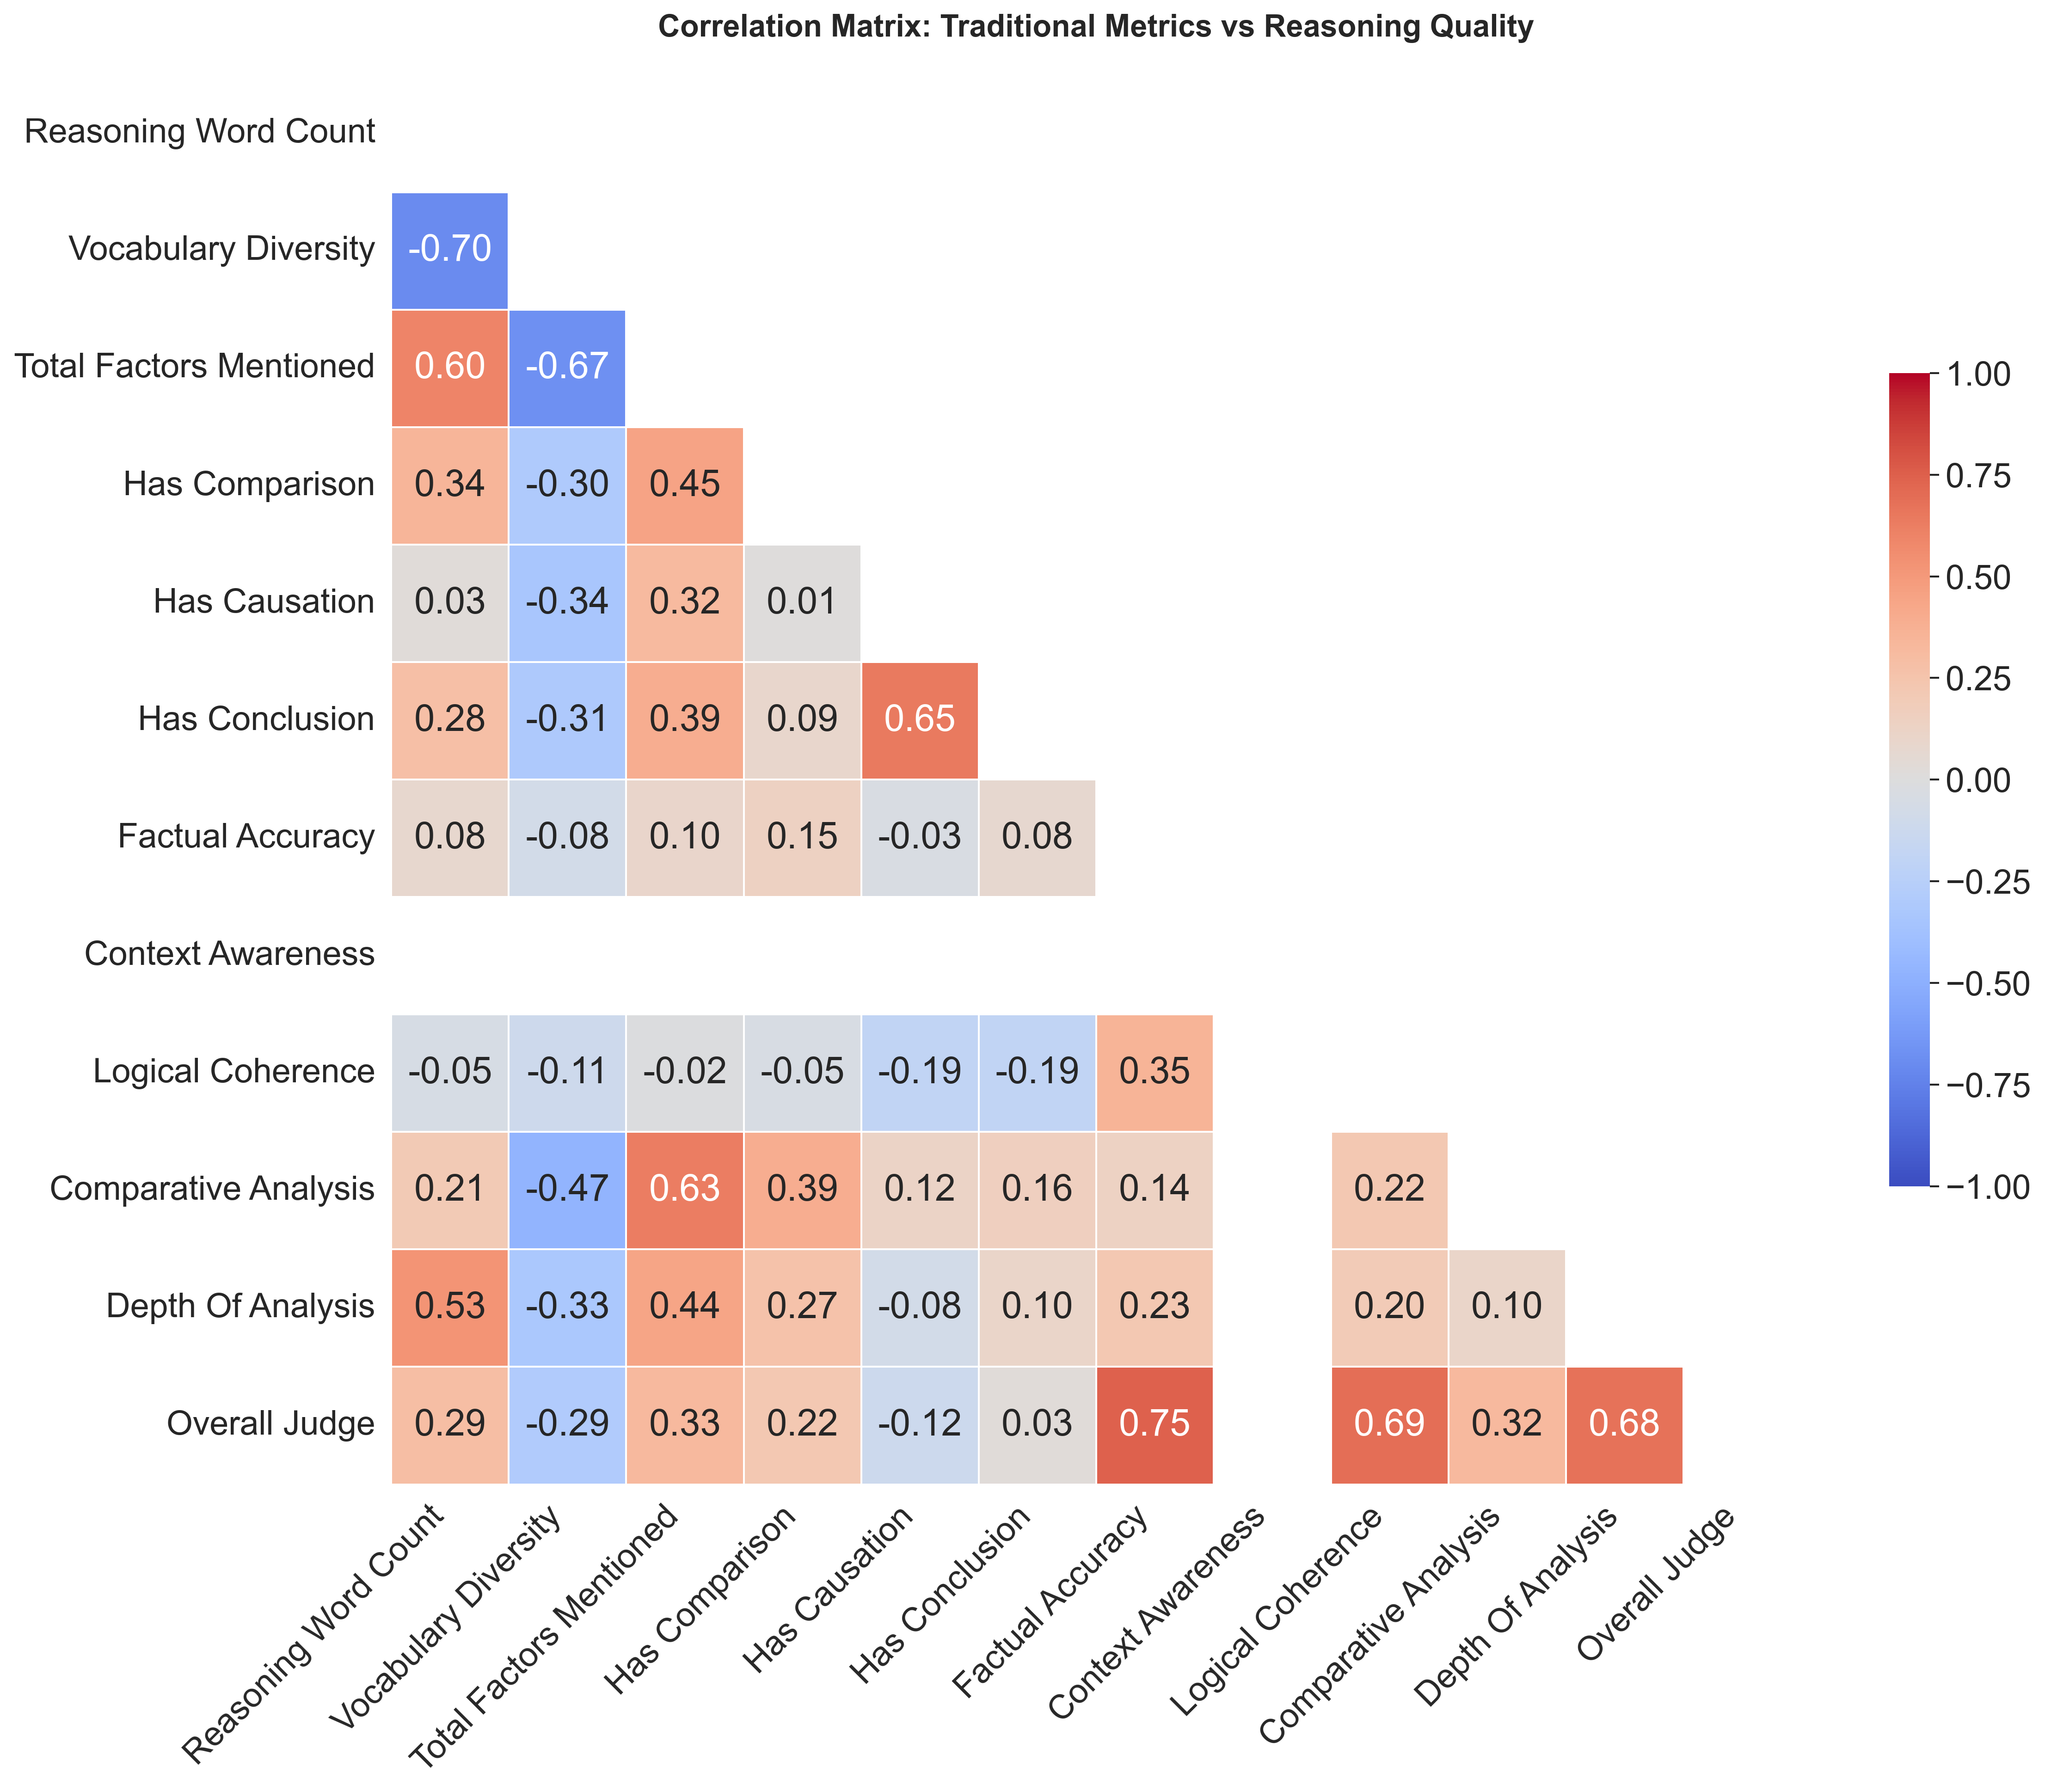


✓ Correlation analysis complete


In [15]:
# Plot 4: Correlation Matrix
# correlation betwen traditional metrics and LLM judge scores

traditional_cols = [
    'reasoning_word_count', 'vocabulary_diversity', 
    'total_factors_mentioned', 'has_comparison', 
    'has_causation', 'has_conclusion'
]
judge_cols = [col for col in analyzed_df.columns if col.endswith('_score')]

if judge_cols:
    # Select numeric columns only
    corr_cols = traditional_cols + judge_cols
    # Ensure valid columns
    corr_cols = [col for col in corr_cols if col in analyzed_df.columns]
    
    # Calculate correlation
    # Force conversion to float for judge scores in case they are objects
    corr_df = analyzed_df[corr_cols].apply(pd.to_numeric, errors='coerce')
    correlation = corr_df.corr()
    
    # Clean up column names for display
    correlation.columns = [c.replace('_score', '').replace('_', ' ').title() for c in correlation.columns]
    correlation.index = [c.replace('_score', '').replace('_', ' ').title() for c in correlation.index]
    
    # Plot
    fig, ax = plt.subplots(figsize=(16, 14))
    mask = np.triu(np.ones_like(correlation, dtype=bool))
    
    sns.heatmap(correlation, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
                annot=True, fmt='.2f', square=True, linewidths=.5, cbar_kws={"shrink": .5}, ax=ax)
    
    ax.set_title('Correlation Matrix: Traditional Metrics vs Reasoning Quality', fontsize=16, fontweight='bold', pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    
    print("\n✓ Correlation analysis complete")


## Save Results

Export all analysis results to CSV files for further analysis.

In [16]:
# Save all results
output_path = analyzer.save_results(OUTPUT_DIR)

print(f"\n{'='*80}")
print("FILES SAVED:")
print(f"{'='*80}")
for file in os.listdir(output_path):
    file_path = os.path.join(output_path, file)
    file_size = os.path.getsize(file_path) / 1024  # KB
    print(f"  ✓ {file} ({file_size:.1f} KB)")

print(f"\n{'='*80}")
print("ANALYSIS COMPLETE!")
print(f"{'='*80}")
print(f"Total samples analyzed: {len(analyzed_df)}")
print(f"Models compared: {len(analyzed_df['model'].unique())}")
print(f"Strategies evaluated: {len(analyzed_df['strategy'].unique())}")
print(f"\nResults directory: {os.path.abspath(output_path)}")


Results saved to ./reasoning_analysis_results/

FILES SAVED:
  ✓ model_comparison.csv (0.6 KB)
  ✓ full_analysis.csv (596.5 KB)
  ✓ model_consistency.csv (0.3 KB)

ANALYSIS COMPLETE!
Total samples analyzed: 70
Models compared: 4
Strategies evaluated: 4

Results directory: /Users/rpenchala/Documents/GitHub/llm-dce/final_analysis/reasoning_analysis_results
